Parameters loaded.
Debug: Parsed 104 notes from solution file.
Calculating optimal angles... (alpha_AT_override = 1.0)
DEBUG: Overriding alpha_AT to 1.0

 --- Cost Breakdown (Calculated in Python) ---
  Position Change (PC): 89.8509
  String Change   (SC): 51.2949
  Angle Transition(AT): 15.4501
  Geo Stretch     (ST): 257.0749
  Phys Action     (DH): 214.7225
  Open String     (NO): 0.0000
----------------------------------------
  Total Cost (Sum)    : 628.3933

 --- Ideal Wrist Angles (Effective Angle) ---
 ※ Angle 0 = Neutral (Perpendicular), Negative = Angled towards bridge
------------------------------------------------------------
 Index Note  Fret  HandPos  Finger  EffAngle
     1   A4    10        9       1    -60.00
     2   A4    10        9       1    -60.00
     3   A4    10        9       1    -60.00
     4   G4    12        9       3    -30.00
     5   F4    10        9       1    -35.00
     6   E4     9        8       1    -35.00
     7   F4    10        8       2    

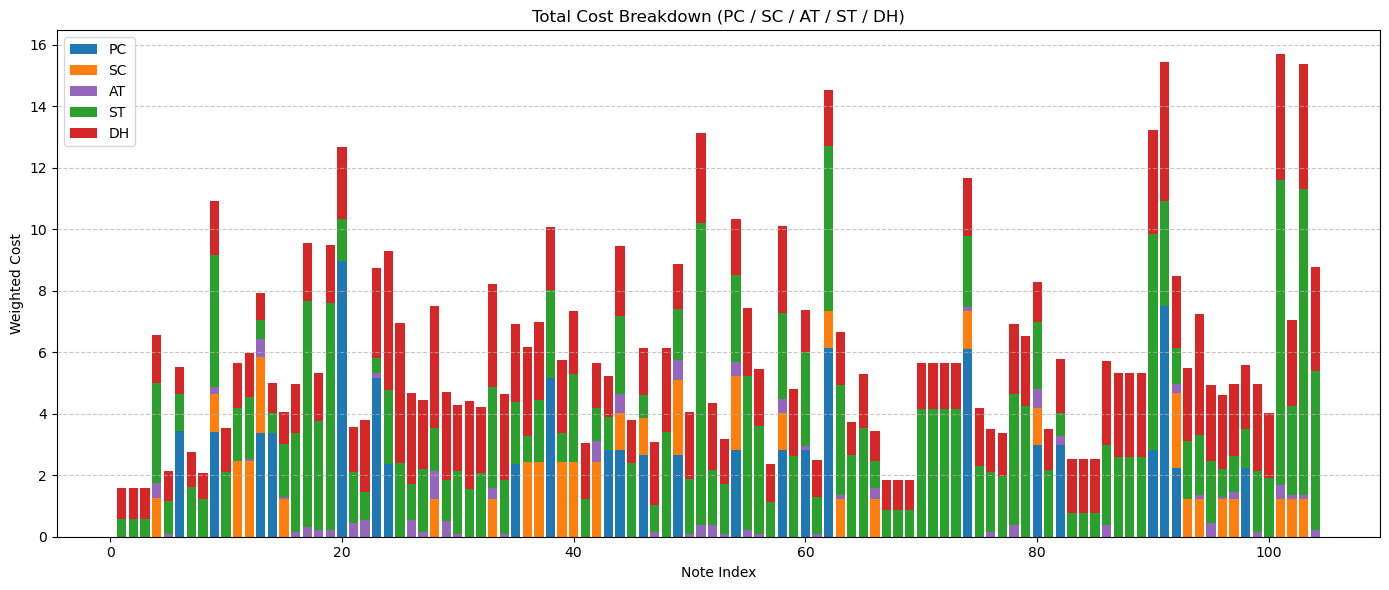

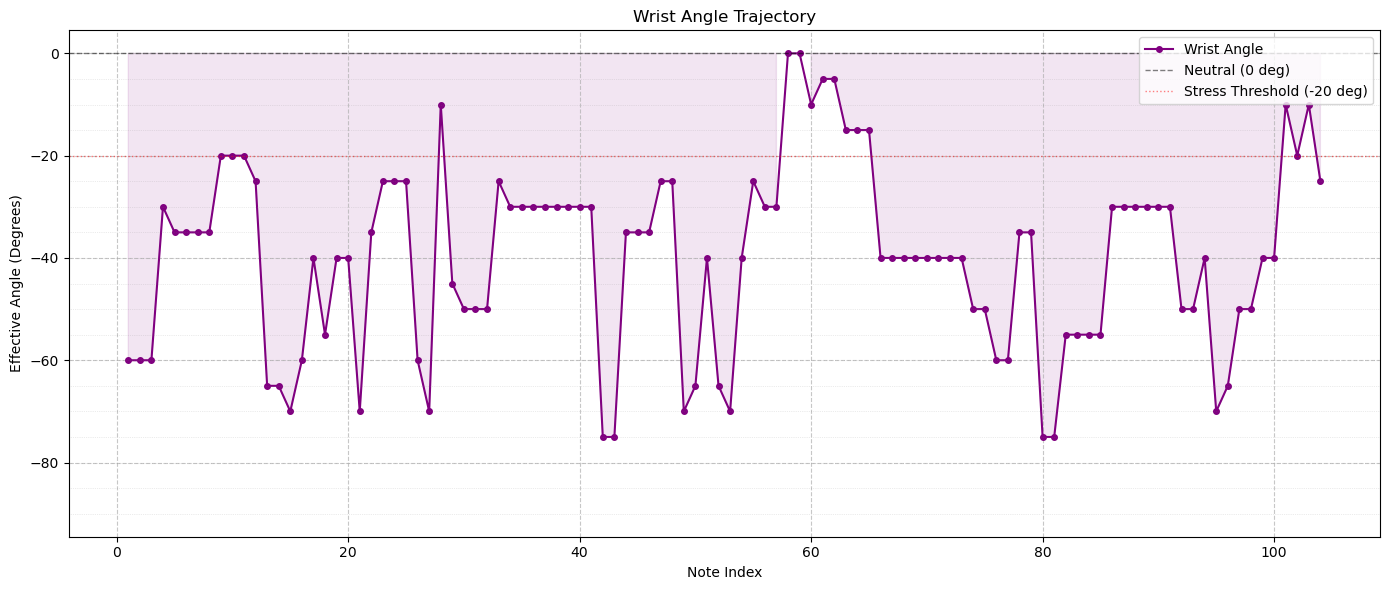

In [73]:
import math
import re
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================================
# 1. Parsing Functions
# ============================================================================

def parse_dat_file(filepath):
    """ .datファイルからパラメータを読み込む """
    params = {}
    if not os.path.exists(filepath):
        print(f"Warning: .dat file '{filepath}' not found. Using defaults.")
        return params

    try:
        with open(filepath, 'r', encoding='utf-8') as f: content = f.read()
    except:
        with open(filepath, 'r', encoding='cp932') as f: content = f.read()

    # コメント除去
    content = re.sub(r'//.*', '', content)
    content = re.sub(r'/\*.*?\*/', '', content, flags=re.DOTALL)

    # スカラー
    for match in re.finditer(r'\b([a-zA-Z0-9_]+)\s*=\s*([-+]?\d*\.?\d+);', content):
        name, val = match.groups()
        params[name] = float(val) if '.' in val else int(val)

    # 配列
    for match in re.finditer(r'\b([a-zA-Z0-9_]+)\s*=\s*\[(.*?)\];', content, re.DOTALL):
        name, val_str = match.groups()
        if '{' in val_str or '}' in val_str: continue 
        try:
            vals = [float(v) for v in re.split(r'[,\s]+', val_str.strip()) if v]
            params[name] = {i+1: v for i,v in enumerate(vals)}
        except ValueError: continue

    return params

def parse_solution_file(filepath):
    """
    OPL解(.txt)のパース。
    Note/String/Fret/HandPos/Fingerを読み取る。
    EffAngleはPython側で再計算・検証するため無視する。
    """
    notes = []
    if not os.path.exists(filepath):
        print(f"Error: File '{filepath}' not found.")
        return []

    try:
        with open(filepath, 'r', encoding='utf-8') as f: lines = f.readlines()
    except:
        with open(filepath, 'r', encoding='cp932', errors='ignore') as f: lines = f.readlines()
    
    for line in lines:
        parts = line.strip().split()
        if not parts: continue
        
        # ヘッダーやゴミ行スキップ
        if "Note" in parts or "---" in parts[0] or "Cost" in parts[0]: continue
        if parts[0] == 'R': continue 

        # Note String Fret HandPos Finger (最低5要素)
        if len(parts) >= 5:
            try:
                # Fingerが 'x' の場合などは 0 にする
                finger_val = int(parts[4]) if parts[4].isdigit() else 0
                
                n = {
                    'NoteName': parts[0],
                    'String': int(parts[1]),
                    'Fret': int(parts[2]),
                    'HandPos': int(parts[3]),
                    'Finger': finger_val,
                    'Duration': 250.0 # 仮のDuration
                }
                notes.append(n)
            except ValueError:
                continue
    
    print(f"Debug: Parsed {len(notes)} notes from solution file.")
    return notes

# ============================================================================
# 2. Optimization & Cost Logic
# ============================================================================

class GuitarOptimizer:
    def __init__(self, params):
        self.p = params
        self.scale_len = params.get('scaleLength', 628.0)
        self.str_spacing = params.get('stringSpacing', 10.8)
        self.f_max = int(params.get('f_max', 22))
        
        # 離散化設定 (OPLモデルに合わせる)
        self.angle_step = 5
        self.max_angle_idx = 18 # 0..18 -> 0度..-90度
        
        self.fret_pos = [self.scale_len - (self.scale_len / (2**(f/12.0))) for f in range(self.f_max+1)]
        
        ns = params.get('natural_min_spread_mm', {1:20, 2:40, 3:55})
        if isinstance(ns, dict):
            self.knuckle_dist = {1:0.0, 2:ns.get(1,20), 3:ns.get(2,40), 4:ns.get(3,55)}
        else:
            self.knuckle_dist = {1:0.0, 2:20, 3:40, 4:55}

        self.reach_coeffs = {1:1.0, 2:0.95, 3:0.90, 4:1.0}
        self.finger_mult = {1:0.3, 2:0.3, 3:0.8, 4:0.9} 
        
        nm = int(params.get('neck_thickness', 1))
        max_red_p16 = {1:0.15, 2:0.20, 3:0.25}.get(nm, 0.20)
        target_red_p12 = 0.03
        if max_red_p16 > target_red_p12:
            self.curve_exp = math.log(target_red_p12/max_red_p16) / math.log(12.0/16.0)
        else:
            self.curve_exp = 1.0
        self.max_reduction = max_red_p16
        
        self.high_limit_base = 30.0
        self.MARGIN_ST = 3.0  # 許容範囲の閾値

        # 物理パラメータ
        self.action_12 = params.get('stringAction12thMm', 2.5)
        self.E_GPa = {1: 179.0, 2: 188.0, 3: 177.0, 4: 62.0, 5: 42.0, 6: 33.0}
        self.Area_m2 = {1: 5.13e-8, 2: 8.56e-8, 3: 1.48e-7, 4: 3.55e-7, 5: 6.79e-7, 6: 1.10e-6}
        self.Tension_N = {1: 73.0, 2: 70.0, 3: 68.0, 4: 75.0, 5: 78.0, 6: 76.0}

    def _get_neck_factor(self, p, f_idx):
        ratio = float(p)/16.0 if p >= 0 else 0.0
        if ratio > 1.0: ratio = 1.0
        reduction = self.max_reduction * (ratio**self.curve_exp) * self.finger_mult.get(f_idx, 0.8)
        return max(0.1, 1.0 - reduction)

    def get_angle_limits(self, finger_idx):
        if finger_idx == 1: return 15.0
        if finger_idx == 2: return 15.0
        if finger_idx == 3: return 20.0
        if finger_idx == 4: return 25.0
        return 15.0

    def calculate_st_cost_for_angle(self, hand_pos, finger_idx, string, fret, angle_deg):
        """ 特定の角度におけるSTコストを計算 (離散化グリッド用) """
        if fret < hand_pos: return 100000.0
        
        pX = self.fret_pos[hand_pos]
        pY = 0.0
        tX = self.fret_pos[fret]
        tY = (string - 1) * self.str_spacing
        
        f_lens = self.p.get('fingerLengths_mm', {1:70,2:75,3:70,4:50})
        f_len = f_lens.get(finger_idx, 70) if isinstance(f_lens, dict) else 70
        base_reach = f_len * self.reach_coeffs.get(finger_idx, 1.0)
        nf = self._get_neck_factor(hand_pos, finger_idx)
        max_reach = base_reach * nf
        
        rad = math.radians(angle_deg)
        dk = self.knuckle_dist.get(finger_idx, 0)
        kX = pX + dk*math.cos(rad)
        kY = pY + dk*math.sin(rad)
        dist = math.sqrt((tX-kX)**2 + (tY-kY)**2)
        
        u_dist = 999.0
        if max_reach > 0.001: u_dist = dist/max_reach
        if u_dist > 1.0: return 100000.0
        
        nX = -math.sin(rad); nY = math.cos(rad)
        dot = (tX-kX)*nX + (tY-kY)*nY
        cos_d = dot/dist if dist > 0.001 else 1.0
        cos_d = max(-1.0, min(1.0, cos_d))
        deg_d = math.degrees(math.acos(cos_d))
        
        cross = nX*(tY-kY) - nY*(tX-kX)
        is_low = (cross > 0)
        
        low_lim = self.get_angle_limits(finger_idx)
        lim_base = self.high_limit_base
        if is_low: lim_base = low_lim
        
        relax = 0.0
        if u_dist < 0.5: relax = 10.0 if is_low else 5.0
        final_lim = lim_base + relax
        
        u_ang = deg_d/final_lim if final_lim > 0 else 999.0
        if u_ang > 1.0: return 100000.0
        
        eps = 0.01
        c_dist = 1.0 * u_dist / (1.0 - u_dist + eps)
        dir_c = 1.5 if is_low else 1.0
        c_angle = (1.0 * dir_c) * u_ang / (1.0 - u_ang + eps)
        
        return c_dist + c_angle

    def get_feasible_grid_costs(self, hand_pos, finger_idx, string, fret):
        """
        OPLの離散化モデル同様、0..18のインデックスに対応するコスト配列を返す。
        有効範囲外は inf とする。
        """
        grid_costs = []
        min_cost = 100000.0
        
        # まず全スキャンして最小コストを見つける（閾値判定のため）
        temp_costs = {}
        for idx in range(self.max_angle_idx + 1):
            deg = -1.0 * idx * self.angle_step
            c = self.calculate_st_cost_for_angle(hand_pos, finger_idx, string, fret, deg)
            temp_costs[idx] = c
            if c < min_cost:
                min_cost = c
        
        threshold = min_cost + self.MARGIN_ST
        
        # 閾値以内のものだけ有効とする
        final_costs = [np.inf] * (self.max_angle_idx + 1)
        if min_cost < 50000.0:
            for idx in range(self.max_angle_idx + 1):
                c = temp_costs[idx]
                if c <= threshold:
                    final_costs[idx] = c
                    
        return final_costs

    def calculate_physics(self, s, f, f_idx):
        """物理コスト(DH)"""
        if f == 0: return 0.0
        a_mm = 0.5 + ((self.action_12 - 0.5)*f/12.0)
        l_mm = self.scale_len - self.fret_pos[f]
        if l_mm < 0.001: return 0.0
        
        lm = l_mm/1000.0; am = a_mm/1000.0
        E = self.E_GPa.get(s, 179)*1e9
        A = self.Area_m2.get(s, 5e-8)
        T = self.Tension_N.get(s, 70)
        
        hyp = math.sqrt(lm**2 + am**2)
        sin_t = am/hyp
        cos_t = lm/hyp
        strain = (1.0/cos_t) - 1.0
        F = (T + E*A*strain)*sin_t
        
        diffs = self.p.get('fingerDifficulty', {1:1,2:1,3:1,4:1})
        diff = diffs.get(f_idx, 1.0) if isinstance(diffs, dict) else 1.0
        return F * 7.5 * diff

    def optimize_angles(self, notes, alpha_at_override=None):
        """
        DPを用いてAT(Angle Transition)コスト + STコストが最小になる角度パスを計算する。
        alpha_at_override: 指定があれば .dat ファイルの値を上書きする
        """
        n_len = len(notes)
        if n_len == 0: return [], []

        # パラメータ取得
        d_AT = self.p.get('d_AT', 1.0)
        
        # Overrideがあればそれを使う (0.0にすればAT無視の挙動が見れる)
        if alpha_at_override is not None:
            alpha_AT = alpha_at_override
            print(f"DEBUG: Overriding alpha_AT to {alpha_AT}")
        else:
            alpha_AT = self.p.get('alpha_AT', 1.0)
            
        d_ST = self.p.get('d_ST', 0.5)
        alpha_ST = self.p.get('alpha_ST', 1.0)

        # 1. 各ステップのグリッドコスト計算
        step_costs = []
        for n in notes:
            if n['Fret'] == 0:
                step_costs.append([0.0] * (self.max_angle_idx + 1))
            else:
                costs = self.get_feasible_grid_costs(n['HandPos'], n['Finger'], n['String'], n['Fret'])
                step_costs.append(costs)

        # 2. DP (Viterbi)
        n_states = self.max_angle_idx + 1
        dp = np.full((n_len, n_states), np.inf)
        parent = np.full((n_len, n_states), -1, dtype=int)
        
        # 初期化
        for k in range(n_states):
            if step_costs[0][k] != np.inf:
                dp[0, k] = step_costs[0][k] * d_ST * alpha_ST
            
        # 遷移
        for i in range(1, n_len):
            prev_valid = False
            for prev_k in range(n_states):
                if dp[i-1, prev_k] != np.inf:
                    prev_valid = True
                    break
            if not prev_valid:
                print(f"Warning: Break in Angle path at index {i}")
                break

            for curr_k in range(n_states):
                st_cost = step_costs[i][curr_k]
                if st_cost == np.inf: continue
                
                weighted_st = st_cost * d_ST * alpha_ST
                best_prev_cost = np.inf
                best_prev_k = -1
                
                for prev_k in range(n_states):
                    if dp[i-1, prev_k] == np.inf: continue
                    
                    # ATコスト
                    diff_idx = abs(curr_k - prev_k)
                    at_cost_val = self.angle_step * diff_idx 
                    weighted_at = at_cost_val * d_AT * alpha_AT
                    
                    total = dp[i-1, prev_k] + weighted_at + weighted_st
                    
                    if total < best_prev_cost:
                        best_prev_cost = total
                        best_prev_k = prev_k
                
                if best_prev_k != -1:
                    dp[i, curr_k] = best_prev_cost
                    parent[i, curr_k] = best_prev_k

        # 3. バックトラック
        opt_angle_indices = [0] * n_len
        best_end_cost = np.inf
        best_end_k = 0
        found = False
        
        for k in range(n_states):
            if dp[-1, k] < best_end_cost:
                best_end_cost = dp[-1, k]
                best_end_k = k
                found = True
        
        if not found:
            print("Warning: Angle Path not found.")
            return [0.0]*n_len, [0.0]*n_len

        curr = best_end_k
        opt_angle_indices[-1] = curr
        for i in range(n_len - 1, 0, -1):
            prev = parent[i, curr]
            opt_angle_indices[i-1] = prev
            curr = prev
            
        # インデックスを角度(deg)に変換
        opt_angles_deg = []
        final_st_costs = []
        for i in range(n_len):
            idx = opt_angle_indices[i]
            deg = -1.0 * idx * self.angle_step
            opt_angles_deg.append(deg)
            raw_st = step_costs[i][idx]
            final_st_costs.append(raw_st if raw_st != np.inf else 0.0)
            
        return opt_angles_deg, final_st_costs

    def run_analysis(self, notes):
        # ★ ここで実験的に ATの重みを変更可能にする
        # 0.0 にすればATコスト無視（常にその場でのベストSTを選択）
        # 1.0 にすれば通常通り（.datファイルの値を使用）
        TEST_ALPHA_AT = 1.0 
        
        print(f"Calculating optimal angles... (alpha_AT_override = {TEST_ALPHA_AT})")
        eff_angles, st_costs_list = self.optimize_angles(notes, alpha_at_override=TEST_ALPHA_AT)
        
        # 時間ペナルティ
        acc_time = 0.0
        tp_factors = []
        prev_dur = None
        for n in notes:
            if prev_dur: acc_time += prev_dur
            else: acc_time = 1000.0
            val = 0.15 + (60.0/(acc_time+0.01))**1.5 if prev_dur else 1.0
            tp_factors.append(val)
            prev_dur = n['Duration']

        # コスト集計
        total = {'PC':0.0, 'SC':0.0, 'AT':0.0, 'ST':0.0, 'DH':0.0, 'NO':0.0}
        details = []
        
        prev_n = None
        prev_ang_deg = 0.0
        
        coeff_PC = self.p.get('d_PC', 1.0) * self.p.get('alpha_PC', 1.0)
        coeff_SC = self.p.get('d_SC', 1.0) * self.p.get('alpha_SC', 1.0)
        # 集計時は元々の係数を使ってコストを表示する（比較のため）
        # もしくは、実験設定と合わせるなら TEST_ALPHA_AT を使うべきだが、
        # ここでは「発生しているAT量」を正しく見るためにdatファイルの値を使う
        coeff_AT = self.p.get('d_AT', 1.0) * self.p.get('alpha_AT', 1.0)
        
        coeff_ST = self.p.get('d_ST', 0.5) * self.p.get('alpha_ST', 1.0)
        coeff_DH = self.p.get('d_DH', 1.2) * self.p.get('alpha_DH', 1.0)
        coeff_NO = self.p.get('d_NO', 10.0) * self.p.get('alpha_NO', 1.0)

        for i, n in enumerate(notes):
            c_st = st_costs_list[i]
            c_dh = 0.0
            c_no = 1.0 if n['Fret'] == 0 else 0.0
            if n['Fret'] > 0:
                c_dh = self.calculate_physics(n['String'], n['Fret'], n['Finger'])
                if c_st >= 50000: c_st = 100000.0
            
            c_pc = 0.0
            c_sc = 0.0
            c_at = 0.0
            curr_ang_deg = eff_angles[i]
            
            if prev_n:
                c_pc = abs(self.fret_pos[n['HandPos']] - self.fret_pos[prev_n['HandPos']])
                c_sc = abs(n['String'] - prev_n['String']) * self.str_spacing
                c_at = abs(curr_ang_deg - prev_ang_deg)
            
            tf = tp_factors[i]
            w_pc = c_pc * tf * coeff_PC
            w_sc = c_sc * tf * coeff_SC
            w_at = c_at * tf * coeff_AT
            w_st = c_st * coeff_ST
            w_dh = c_dh * coeff_DH
            w_no = c_no * coeff_NO
            
            row_sum = w_pc + w_sc + w_at + w_st + w_dh + w_no
            
            total['PC'] += w_pc
            total['SC'] += w_sc
            total['AT'] += w_at
            total['ST'] += w_st
            total['DH'] += w_dh
            total['NO'] += w_no
            
            details.append({
                'Index': i+1,
                'Note': n['NoteName'],
                'Fret': n['Fret'],
                'HandPos': n['HandPos'],
                'Finger': n['Finger'],
                'EffAngle': curr_ang_deg,
                'PC_w': w_pc, 'SC_w': w_sc, 'AT_w': w_at, 'ST_w': w_st, 'DH_w': w_dh, 'NO_w': w_no,
                'Total': row_sum
            })
            prev_n = n
            prev_ang_deg = curr_ang_deg
            
        return total, details

# ============================================================================
# 3. Main
# ============================================================================
if __name__ == "__main__":
    dat_f = 'datas/complex_solo_mod.dat'
    sol_f = 'complex_opt.txt'
    
    params = parse_dat_file(dat_f)
    print("Parameters loaded.")
    
    notes = parse_solution_file(sol_f)
    
    if notes:
        optimizer = GuitarOptimizer(params)
        totals, details = optimizer.run_analysis(notes)
        
        print("\n" + "="*60)
        print(" --- Cost Breakdown (Calculated in Python) ---")
        print(f"  Position Change (PC): {totals['PC']:.4f}")
        print(f"  String Change   (SC): {totals['SC']:.4f}")
        print(f"  Angle Transition(AT): {totals['AT']:.4f}")
        print(f"  Geo Stretch     (ST): {totals['ST']:.4f}")
        print(f"  Phys Action     (DH): {totals['DH']:.4f}")
        print(f"  Open String     (NO): {totals['NO']:.4f}")
        print("-" * 40)
        print(f"  Total Cost (Sum)    : {sum(totals.values()):.4f}")
        print("="*60)
        
        df = pd.DataFrame(details)
        if not df.empty:
            df.to_csv('final_cost_analysis.csv', index=False)
            
            print("\n" + "="*60)
            print(" --- Ideal Wrist Angles (Effective Angle) ---")
            print(" ※ Angle 0 = Neutral (Perpendicular), Negative = Angled towards bridge")
            print("-" * 60)
            pd.set_option('display.max_rows', None)
            print(df[['Index', 'Note', 'Fret', 'HandPos', 'Finger', 'EffAngle']].to_string(index=False, float_format="%.2f"))

            # --- Graphs ---
            # 1. Stacked Bar Chart
            plt.figure(figsize=(14, 6))
            idx = df['Index']
            p1 = plt.bar(idx, df['PC_w'], label='PC', color='#1f77b4')
            p2 = plt.bar(idx, df['SC_w'], bottom=df['PC_w'], label='SC', color='#ff7f0e')
            p3 = plt.bar(idx, df['AT_w'], bottom=df['PC_w']+df['SC_w'], label='AT', color='#9467bd')
            p4 = plt.bar(idx, df['ST_w'], bottom=df['PC_w']+df['SC_w']+df['AT_w'], label='ST', color='#2ca02c')
            p5 = plt.bar(idx, df['DH_w'], bottom=df['PC_w']+df['SC_w']+df['AT_w']+df['ST_w'], label='DH', color='#d62728')
            
            plt.xlabel('Note Index')
            plt.ylabel('Weighted Cost')
            plt.title('Total Cost Breakdown (PC / SC / AT / ST / DH)')
            plt.legend()
            plt.grid(axis='y', linestyle='--', alpha=0.7)
            plt.tight_layout()
            
            # 2. Angle Trajectory
            plt.figure(figsize=(14, 6))
            plt.plot(df['Index'], df['EffAngle'], marker='o', markersize=4, linestyle='-', linewidth=1.5, color='purple', label='Wrist Angle')
            
            for y in range(0, -95, -5):
                plt.axhline(y=y, color='gray', linestyle=':', linewidth=0.5, alpha=0.3)
                
            plt.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Neutral (0 deg)')
            plt.axhline(y=-20, color='red', linestyle=':', linewidth=1, alpha=0.5, label='Stress Threshold (-20 deg)')
            
            plt.fill_between(df['Index'], df['EffAngle'], 0, where=(df['EffAngle'] < 0), color='purple', alpha=0.1)
            plt.xlabel('Note Index')
            plt.ylabel('Effective Angle (Degrees)')
            plt.title('Wrist Angle Trajectory')
            plt.legend(loc='upper right')
            plt.grid(True, linestyle='--', alpha=0.7)
            plt.tight_layout()
            
            plt.show()
            
    else:
        print("No notes found to analyze.")

Parameters loaded.

 --- Raw Cost Statistics (Before Weighting) ---
 ※ These values show the 'variability' and 'magnitude' of each cost type.
------------------------------------------------------------
       PC   SC   AT   ST   DH
mean 0.86 0.66 1.49 2.47 4.13
std  1.80 1.10 2.06 1.92 1.73
max  8.97 3.29 9.04 9.94 9.06
------------------------------------------------------------
 --- Recommended Weights (Calculated from Std Dev) ---
 Logic: Weight = (PC_std * Target_Ratio) / My_std
------------------------------------------------------------
 PC : Raw Std=  1.80 | Target Ratio=1.0 -> Rec Weight=1.0000
 SC : Raw Std=  1.10 | Target Ratio=1.2 -> Rec Weight=1.9614
 AT : Raw Std=  2.06 | Target Ratio=0.4 -> Rec Weight=0.3499
 ST : Raw Std=  1.92 | Target Ratio=0.8 -> Rec Weight=0.7499
 DH : Raw Std=  1.73 | Target Ratio=0.6 -> Rec Weight=0.6224


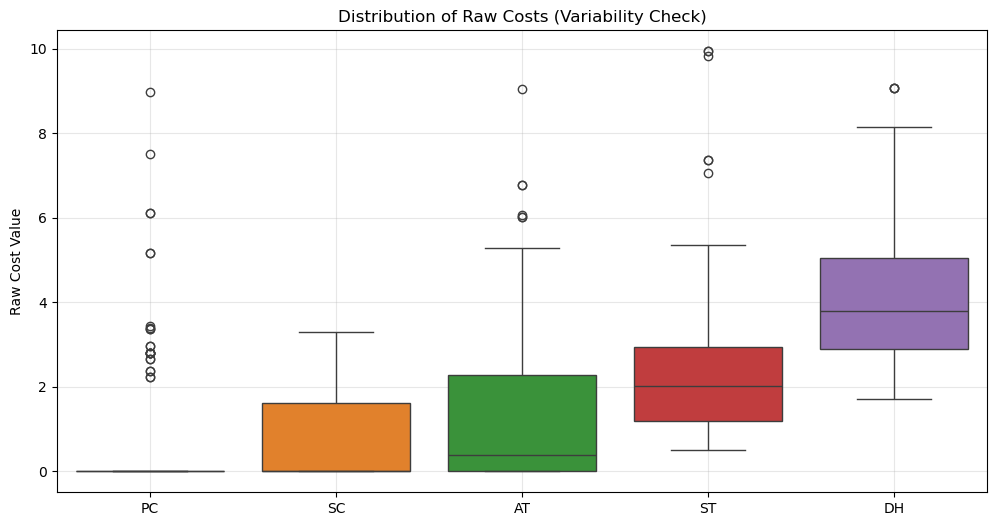


[Action] You can update your .dat file with these values:
d_PC = 1.00;
d_SC = 1.96;
d_AT = 0.35;
d_ST = 0.75;
d_DH = 0.62;


In [ ]:
import math
import re
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# 1. Parsing Functions (Existing)
# ============================================================================
def parse_dat_file(filepath):
    """ .datファイルからパラメータを読み込む """
    params = {}
    if not os.path.exists(filepath): return params
    try:
        with open(filepath, 'r', encoding='utf-8') as f: content = f.read()
    except:
        with open(filepath, 'r', encoding='cp932') as f: content = f.read()
    content = re.sub(r'//.*', '', content)
    content = re.sub(r'/\*.*?\*/', '', content, flags=re.DOTALL)
    for match in re.finditer(r'\b([a-zA-Z0-9_]+)\s*=\s*([-+]?\d*\.?\d+);', content):
        name, val = match.groups()
        params[name] = float(val) if '.' in val else int(val)
    for match in re.finditer(r'\b([a-zA-Z0-9_]+)\s*=\s*\[(.*?)\];', content, re.DOTALL):
        name, val_str = match.groups()
        if '{' in val_str or '}' in val_str: continue 
        try:
            vals = [float(v) for v in re.split(r'[,\s]+', val_str.strip()) if v]
            params[name] = {i+1: v for i,v in enumerate(vals)}
        except ValueError: continue
    return params

def parse_solution_file(filepath):
    """ OPL解(.txt)のパース """
    notes = []
    if not os.path.exists(filepath): return []
    try:
        with open(filepath, 'r', encoding='utf-8') as f: lines = f.readlines()
    except:
        with open(filepath, 'r', encoding='cp932', errors='ignore') as f: lines = f.readlines()
    for line in lines:
        parts = line.strip().split()
        if not parts: continue
        if "Note" in parts or "---" in parts[0] or "Cost" in parts[0]: continue
        if parts[0] == 'R': continue 
        if len(parts) >= 5:
            try:
                finger_val = int(parts[4]) if parts[4].isdigit() else 0
                n = {'NoteName': parts[0], 'String': int(parts[1]), 'Fret': int(parts[2]),
                     'HandPos': int(parts[3]), 'Finger': finger_val, 'Duration': 250.0}
                notes.append(n)
            except ValueError: continue
    return notes

# ============================================================================
# 2. Optimization Logic (Refined)
# ============================================================================
class GuitarOptimizer:
    def __init__(self, params):
        self.p = params
        self.scale_len = params.get('scaleLength', 628.0)
        self.str_spacing = params.get('stringSpacing', 10.8)
        self.f_max = int(params.get('f_max', 22))
        self.angle_step = 5
        self.max_angle_idx = 18 
        self.fret_pos = [self.scale_len - (self.scale_len / (2**(f/12.0))) for f in range(self.f_max+1)]
        ns = params.get('natural_min_spread_mm', {1:20, 2:40, 3:55})
        self.knuckle_dist = {1:0.0, 2:ns.get(1,20), 3:ns.get(2,40), 4:ns.get(3,55)} if isinstance(ns, dict) else {1:0.0, 2:20, 3:40, 4:55}
        self.reach_coeffs = {1:1.0, 2:0.95, 3:0.90, 4:1.0}
        self.finger_mult = {1:0.3, 2:0.3, 3:0.8, 4:0.9} 
        nm = int(params.get('neck_thickness', 1))
        max_red_p16 = {1:0.15, 2:0.20, 3:0.25}.get(nm, 0.20)
        self.curve_exp = math.log(0.03/max_red_p16) / math.log(12.0/16.0) if max_red_p16 > 0.03 else 1.0
        self.max_reduction = max_red_p16
        self.high_limit_base = 30.0
        self.MARGIN_ST = 3.0
        self.action_12 = params.get('stringAction12thMm', 2.5)
        self.E_GPa = {1: 179.0, 2: 188.0, 3: 177.0, 4: 62.0, 5: 42.0, 6: 33.0}
        self.Area_m2 = {1: 5.13e-8, 2: 8.56e-8, 3: 1.48e-7, 4: 3.55e-7, 5: 6.79e-7, 6: 1.10e-6}
        self.Tension_N = {1: 73.0, 2: 70.0, 3: 68.0, 4: 75.0, 5: 78.0, 6: 76.0}

    def _get_neck_factor(self, p, f_idx):
        ratio = float(p)/16.0 if p >= 0 else 0.0
        if ratio > 1.0: ratio = 1.0
        reduction = self.max_reduction * (ratio**self.curve_exp) * self.finger_mult.get(f_idx, 0.8)
        return max(0.1, 1.0 - reduction)

    def get_angle_limits(self, finger_idx):
        return {1:15.0, 2:15.0, 3:20.0, 4:25.0}.get(finger_idx, 15.0)

    def calculate_st_cost_for_angle(self, hand_pos, finger_idx, string, fret, angle_deg):
        if fret < hand_pos: return 100000.0
        pX = self.fret_pos[hand_pos]; pY = 0.0
        tX = self.fret_pos[fret]; tY = (string - 1) * self.str_spacing
        f_len = self.p.get('fingerLengths_mm', {1:70}).get(finger_idx, 70)
        base_reach = f_len * self.reach_coeffs.get(finger_idx, 1.0)
        max_reach = base_reach * self._get_neck_factor(hand_pos, finger_idx)
        
        rad = math.radians(angle_deg)
        dk = self.knuckle_dist.get(finger_idx, 0)
        kX = pX + dk*math.cos(rad); kY = pY + dk*math.sin(rad)
        dist = math.sqrt((tX-kX)**2 + (tY-kY)**2)
        
        u_dist = dist/max_reach if max_reach > 0.001 else 999.0
        if u_dist > 1.0: return 100000.0
        
        nX = -math.sin(rad); nY = math.cos(rad)
        dot = (tX-kX)*nX + (tY-kY)*nY
        cos_d = max(-1.0, min(1.0, dot/dist if dist > 0.001 else 1.0))
        deg_d = math.degrees(math.acos(cos_d))
        
        is_low = (nX*(tY-kY) - nY*(tX-kX) > 0)
        lim_base = self.get_angle_limits(finger_idx) if is_low else self.high_limit_base
        final_lim = lim_base + (10.0 if is_low else 5.0) if u_dist < 0.5 else lim_base
        
        u_ang = deg_d/final_lim if final_lim > 0 else 999.0
        if u_ang > 1.0: return 100000.0
        
        c_dist = u_dist / (1.0 - u_dist + 0.01)
        c_angle = (1.5 if is_low else 1.0) * u_ang / (1.0 - u_ang + 0.01)
        return c_dist + c_angle

    def get_feasible_grid_costs(self, hand_pos, finger_idx, string, fret):
        temp_costs = {}
        min_cost = 100000.0
        for idx in range(self.max_angle_idx + 1):
            deg = -1.0 * idx * self.angle_step
            c = self.calculate_st_cost_for_angle(hand_pos, finger_idx, string, fret, deg)
            temp_costs[idx] = c
            if c < min_cost: min_cost = c
        
        threshold = min_cost + self.MARGIN_ST
        final_costs = [np.inf] * (self.max_angle_idx + 1)
        if min_cost < 50000.0:
            for idx in range(self.max_angle_idx + 1):
                if temp_costs[idx] <= threshold: final_costs[idx] = temp_costs[idx]
        return final_costs

    def calculate_physics(self, s, f, f_idx):
        if f == 0: return 0.0
        a_mm = 0.5 + ((self.action_12 - 0.5)*f/12.0)
        l_mm = self.scale_len - self.fret_pos[f]
        if l_mm < 0.001: return 0.0
        
        E = self.E_GPa.get(s, 179)*1e9
        A = self.Area_m2.get(s, 5e-8)
        T = self.Tension_N.get(s, 70)
        
        sin_t = (a_mm/1000.0)/math.sqrt((l_mm/1000.0)**2 + (a_mm/1000.0)**2)
        strain = (1.0/(l_mm/1000.0 * math.sqrt((l_mm/1000.0)**2 + (a_mm/1000.0)**2)**-1)) - 1.0 # approx
        strain = math.sqrt(1 + (a_mm/l_mm)**2) - 1.0
        F = (T + E*A*strain)*sin_t
        diff = self.p.get('fingerDifficulty', {1:1}).get(f_idx, 1.0)
        return F * 7.5 * diff

    def optimize_angles(self, notes):
        n_len = len(notes)
        if n_len == 0: return [], []
        d_AT, alpha_AT = self.p.get('d_AT', 0.5), self.p.get('alpha_AT', 1.0)
        d_ST, alpha_ST = self.p.get('d_ST', 0.35), self.p.get('alpha_ST', 1.0)

        step_costs = []
        for n in notes:
            if n['Fret'] == 0: step_costs.append([0.0] * (self.max_angle_idx + 1))
            else: step_costs.append(self.get_feasible_grid_costs(n['HandPos'], n['Finger'], n['String'], n['Fret']))

        n_states = self.max_angle_idx + 1
        dp = np.full((n_len, n_states), np.inf)
        parent = np.full((n_len, n_states), -1, dtype=int)
        
        for k in range(n_states):
            if step_costs[0][k] != np.inf: dp[0, k] = step_costs[0][k] * d_ST * alpha_ST
            
        for i in range(1, n_len):
            for curr_k in range(n_states):
                st_cost = step_costs[i][curr_k]
                if st_cost == np.inf: continue
                weighted_st = st_cost * d_ST * alpha_ST
                
                best_prev_cost = np.inf
                best_prev_k = -1
                for prev_k in range(n_states):
                    if dp[i-1, prev_k] == np.inf: continue
                    at_val = self.angle_step * abs(curr_k - prev_k)
                    total = dp[i-1, prev_k] + (at_val * d_AT * alpha_AT) + weighted_st
                    if total < best_prev_cost: best_prev_cost = total; best_prev_k = prev_k
                
                if best_prev_k != -1: dp[i, curr_k] = best_prev_cost; parent[i, curr_k] = best_prev_k

        opt_angle_indices = [0] * n_len
        best_end_k = np.argmin(dp[-1])
        if dp[-1, best_end_k] == np.inf: return [0.0]*n_len, [0.0]*n_len

        curr = best_end_k
        opt_angle_indices[-1] = curr
        for i in range(n_len - 1, 0, -1):
            curr = parent[i, curr]
            opt_angle_indices[i-1] = curr
            
        opt_angles_deg = [-1.0 * k * self.angle_step for k in opt_angle_indices]
        final_st_costs = [step_costs[i][k] if step_costs[i][k] != np.inf else 0.0 for i, k in enumerate(opt_angle_indices)]
        return opt_angles_deg, final_st_costs

    def analyze_stats(self, notes):
        """ 生コストの統計分析と推奨ウェイトの計算 """
        eff_angles, st_costs_list = self.optimize_angles(notes)
        
        # Raw Costs (係数をかける前の値) を収集
        raw_data = []
        acc_time = 0.0
        prev_dur = None
        prev_n = None
        prev_ang = 0.0
        
        for i, n in enumerate(notes):
            if prev_dur: acc_time += prev_dur
            else: acc_time = 1000.0
            tf = 0.15 + (60.0/(acc_time+0.01))**1.5 if prev_dur else 1.0
            prev_dur = n['Duration']
            
            c_pc = abs(self.fret_pos[n['HandPos']] - self.fret_pos[prev_n['HandPos']]) if prev_n else 0.0
            c_sc = abs(n['String'] - prev_n['String']) * self.str_spacing if prev_n else 0.0
            c_at = abs(eff_angles[i] - prev_ang) if prev_n else 0.0
            c_st = st_costs_list[i] if st_costs_list[i] < 50000 else 0.0
            c_dh = self.calculate_physics(n['String'], n['Fret'], n['Finger']) if n['Fret'] > 0 else 0.0
            
            # 生データ保存 (時間ペナルティ込みの生変動要素)
            raw_data.append({
                'PC': c_pc * tf,
                'SC': c_sc * tf,
                'AT': c_at * tf,
                'ST': c_st,
                'DH': c_dh
            })
            prev_n = n; prev_ang = eff_angles[i]
            
        df_raw = pd.DataFrame(raw_data)
        
        print("\n" + "="*60)
        print(" --- Raw Cost Statistics (Before Weighting) ---")
        print(" ※ These values show the 'variability' and 'magnitude' of each cost type.")
        print("-" * 60)
        stats = df_raw.describe().loc[['mean', 'std', 'max']]
        print(stats.to_string(float_format="%.2f"))
        
        # --- 推奨ウェイトの計算 ---
        # 目標とする「影響力比率 (Target Impact Ratio)」
        # PC(1.0)を基準として、各要素の標準偏差(std)をどれくらい揃えるか
        target_ratios = {
            'PC': 1.0,  # 基準
            'SC': 1.2,  # PCより少し優先（ピッキングは重要）
            'AT': 0.4,  # SCの1/3程度（ダンパー役割）
            'ST': 0.8,  # PCより少し低め（無理な形だけ弾ければいい）
            'DH': 0.6   # 物理負荷も同様
        }
        
        print("-" * 60)
        print(" --- Recommended Weights (Calculated from Std Dev) ---")
        print(" Logic: Weight = (PC_std * Target_Ratio) / My_std")
        print("-" * 60)
        
        pc_std = stats.loc['std', 'PC'] if stats.loc['std', 'PC'] > 0 else 1.0
        
        recs = {}
        for col in ['PC', 'SC', 'AT', 'ST', 'DH']:
            my_std = stats.loc['std', col]
            if my_std < 0.001: my_std = 0.1 # ゼロ除算防止
            
            # PCの変動量を基準にスケーリング
            weight = (pc_std * target_ratios[col]) / my_std
            recs[col] = weight
            print(f" {col:2} : Raw Std={my_std:6.2f} | Target Ratio={target_ratios[col]:.1f} -> Rec Weight={weight:.4f}")

        # 箱ひげ図で分散を可視化
        plt.figure(figsize=(12, 6))
        # スケールが違いすぎるので正規化して表示するか、そのまま表示するか
        # ここでは生データのばらつきを見たいのでそのまま表示（対数軸推奨）
        sns.boxplot(data=df_raw)
        plt.title('Distribution of Raw Costs (Variability Check)')
        plt.ylabel('Raw Cost Value')
        plt.grid(True, alpha=0.3)
        plt.show()

        return recs

# ============================================================================
# 3. Main
# ============================================================================
if __name__ == "__main__":
    dat_f = 'datas/august.dat'
    sol_f = 'august_opt.txt'
    
    params = parse_dat_file(dat_f)
    print("Parameters loaded.")
    notes = parse_solution_file(sol_f)
    
    if notes:
        opt = GuitarOptimizer(params)
        
        # 統計分析と推奨値の算出
        rec_weights = opt.analyze_stats(notes)
        
        print("\n[Action] You can update your .dat file with these values:")
        for k, v in rec_weights.items():
            print(f"d_{k} = {v:.2f};")

    else:
        print("No notes found.")

